# C3 · iTutorGroup: auditing an explicit rejection rule

**Case:** EEOC (11 September 2023), iTutorGroup settlement.  
**Official source:** https://www.eeoc.gov/newsroom/itutorgroup-pay-365000-settle-eeoc-discriminatory-hiring-suit  
**Evidence:** an official case summary, with a clearly labelled reconstruction of the alleged age/sex rule. The source does not supply applicant-level records. Our 36 boundary-test rows and work-sample target are fictional.  
**Full guided lesson:** about 60–75 minutes.  
**Learning goal:** recognize discriminatory decision logic, test rule boundaries and propose a process correction without inventing actual applicant rates.

### How students use this notebook

Run cells in order. Pause at every **Student task** and record your expectation before showing the worked answer. Name the numerator, denominator, unit and decision rule beside each reported number. The raw folder preserves inputs; the processed folder holds documented teaching tables. Rebuild processed data with `python scripts/process_data.py` from the package root. The source manifest records download versions and distinguishes generated inputs.

For the 150-minute lesson, your team completes the core sections assigned in `INSTRUCTOR_GUIDE.md`. The full notebook takes longer and can support self-study. Part 2 is deliberately unfinished. Running Part 1 supplies a baseline; it does not constitute a final project. Use only data whose provenance and permitted use you can explain.

**Instructor / course:** ____________________  
**Student / team / date:** ____________________

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "data/DATA_MANIFEST.json").exists())
sys.path.insert(0, str(ROOT / "src"))
from fairness_lab import (load_table, audit_table, confusion_counts, rates, rate_gaps,
    wilson_interval, bootstrap_mean_interval, paired_summary, matching_scores, alleged_age_veto)
SEED=42
pd.set_option("display.max_columns",25)
pd.set_option("display.max_rows",25)
pd.set_option("display.float_format",lambda x:f"{x:.4f}")
plt.rcParams.update({"figure.figsize":(9,4.5),"axes.spines.top":False,
    "axes.spines.right":False,"font.size":11})
%matplotlib inline
print("Local data only. No API key, paid model, or live LLM is needed.")

Local data only. No API key, paid model, or live LLM is needed.


## Part 1 — Case interpretation, engineering and a worked rule audit

### 1.1 What the official case establishes

The EEOC reported a $365,000 settlement resolving allegations that tutor application software rejected female applicants aged 55 or older and male applicants aged 60 or older. It reported more than 200 qualified U.S.-based applicants affected. The mechanism described was programmed decision logic. This source does not establish that an LLM or trained statistical classifier produced the rejection.

The source describes a settlement, not a verdict after a completed trial. It also reports preventive relief, including training, a revised policy, restrictions on discriminatory screening and requesting birth dates, monitoring, and recontact/interview provisions if U.S. hiring resumes. These are source case facts, not actions carried out by this notebook.

**Student task:** Why would classifier accuracy be an incomplete response to this problem? Which specific input and branch should an auditor inspect? Why cannot “more than 200” be converted into the percentage of all applicants rejected?

In [2]:
facts=json.loads((ROOT/"data/raw/03_itutorgroup/CASE_FACTS.json").read_text())
display(pd.Series(facts["reported_allegation"],name="Reported allegation"))
print("Settlement amount:",facts["settlement_usd"],"USD")
display(pd.Series(facts["unknown"],name="Information the source does not supply"))

female_min_rejection_age                    55
male_min_rejection_age                      60
affected_qualified_applicants    more than 200
Name: Reported allegation, dtype: object

Settlement amount: 365000 USD


0    complete applicant features
1         all applicant outcomes
2         job-performance labels
3                 sampling frame
Name: Information the source does not supply, dtype: object

### 1.2 Dataset, features and targets

| Role | Known from the source | What this notebook supplies |
|---|---|---|
| Observations | No applicant-level dataset or complete sampling frame | 36 invented boundary rows: nine ages × two rule categories × two eligibility states |
| Rule features | Age and female/male category enter the reported veto | `age_years`, `sex_rule_category`; their names describe the reported rule |
| Other application features | Full feature list unavailable | Fictional `work_sample` values 80 and 50 to illustrate a separate job-related rubric |
| Software output | Automatic rejection | Reconstructed `veto` and `decision_legacy` |
| Reference target | Source calls affected applicants qualified, but supplies no full labels | `teaching_eligible`/`y`: invented work sample ≥70 |
| Independent job success | Not supplied | Still absent. The constructed reference does not measure actual teaching performance |

The sample intentionally concentrates on ages near the boundaries. It cannot estimate actual workforce demographics, employer selection rates, legal damages per applicant or effects in Germany. The female/male tags reproduce the two categories described in the allegation; they are not an exhaustive description of gender identities. The source does not specify how other categories were handled, so our rule helper raises an error rather than inventing that policy.

### 1.3 Raw loader and data engineering

**Student task:** Name two fields that belong in a restricted audit file but might be unnecessary in operational screening. Explain why copying every raw field into an applicant interface would be a poor data-minimization choice.

In [3]:
raw=pd.read_csv(ROOT/"data/raw/03_itutorgroup/synthetic_applicants.csv")
data=load_table("03_itutorgroup","applicant_grid.csv")
assert len(raw)==len(data)==36 and data.applicant_id.is_unique
assert data.age_years.isin([30,40,54,55,56,59,60,61,70]).all()
assert set(data.sex_rule_category)=={"female","male"}
assert data.y.eq(data.work_sample.ge(70).astype(int)).all()
assert data.provenance.str.contains("generated boundary grid").all()
display(data[["applicant_id","age_years","sex_rule_category","work_sample","y","age_band"]].head(12))
display(data.groupby(["age_band","sex_rule_category"],observed=True).size().unstack())

,applicant_id,age_years,sex_rule_category,work_sample,y,age_band
0,T001,30,female,50,0,under 55
1,T002,30,female,80,1,under 55
2,T003,30,male,50,0,under 55
3,T004,30,male,80,1,under 55
4,T005,40,female,50,0,under 55
5,T006,40,female,80,1,under 55
6,T007,40,male,50,0,under 55
7,T008,40,male,80,1,under 55
8,T009,54,female,50,0,under 55
9,T010,54,female,80,1,under 55


sex_rule_category,female,male
age_band,,
55–59,6,6
60 and over,6,6
under 55,6,6


### 1.4 Boundary tests expose the mechanism

The reconstructed age veto is true for female-category rows at age ≥55 or male-category rows at age ≥60. It does not inspect teaching qualifications. For the worked pipeline, `decision_legacy = teaching_eligible AND NOT veto`. That qualification step is our invented teaching scaffold; only the veto follows the reported allegation.

**Student task:** Predict the decisions for an otherwise identical eligible 55-year-old in each rule category. Repeat at 54, 59 and 60. State the boundary convention (inclusive ≥). A one-year boundary change can determine access to the next hiring stage.

The following table holds the invented qualification state fixed. It is a treatment test with a known mechanism, rather than a test of trained-model accuracy.

sex_rule_category,female,male
age_years,,
54,1,1
55,0,1
59,0,1
60,0,0


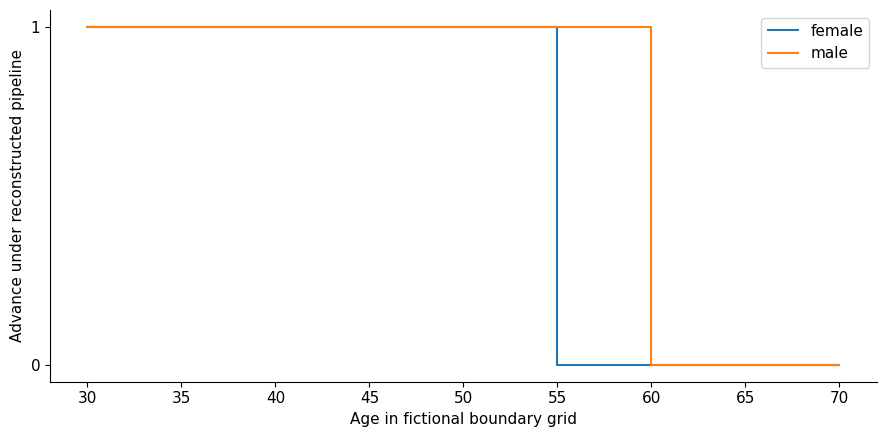

In [4]:
data["veto"]=alleged_age_veto(data)
data["decision_legacy"]=(data.y.eq(1)&~data.veto).astype(int)
eligible=data.loc[data.y.eq(1)]
boundary=eligible.pivot(index="age_years",columns="sex_rule_category",values="decision_legacy")
display(boundary.loc[[54,55,59,60]])
assert boundary.loc[54].eq(1).all()
assert boundary.loc[55,"female"]==0 and boundary.loc[55,"male"]==1
assert boundary.loc[60].eq(0).all()
fig,ax=plt.subplots()
for category,part in eligible.groupby("sex_rule_category"):
    part=part.sort_values("age_years")
    ax.step(part.age_years,part.decision_legacy,where="post",label=category)
ax.set_xlabel("Age in fictional boundary grid");ax.set_ylabel("Advance under reconstructed pipeline")
ax.set_yticks([0,1]);ax.legend();plt.tight_layout();plt.show()

### 1.5 Direct comparisons and intersectional diagnosis

At each age and qualification state, compare the two rule categories. Then compare adjacent ages within a category. A pooled selection rate can conceal the exact branch: the sex difference occurs at ages 55–59, whereas both categories face the veto at 60+. Inspect intersections and boundary cases before writing a generalized conclusion.

**Student task:** Are all veto flips also decision flips? An ineligible profile can be rejected by both branches despite different veto values. Distinguish a rule component from the final pipeline output.

In [5]:
paired=data.pivot(index=["age_years","work_sample"],columns="sex_rule_category",values="decision_legacy")
paired["female_minus_male"]=paired.female-paired.male
paired["decision_flip"]=paired.female.ne(paired.male)
display(paired)
print("Pipeline flips:",int(paired.decision_flip.sum()),"of",len(paired),"fictional pairs")
assert paired.decision_flip.sum()==3
intersections=data.groupby(["age_band","sex_rule_category"],observed=True).agg(
    rows=("applicant_id","size"),eligible=("y","sum"),advanced=("decision_legacy","sum"))
display(intersections)

sex_rule_category      female  male  female_minus_male  decision_flip
age_years work_sample                                                
30        50                0     0                  0          False
          80                1     1                  0          False
40        50                0     0                  0          False
          80                1     1                  0          False
54        50                0     0                  0          False
          80                1     1                  0          False
55        50                0     0                  0          False
          80                0     1                 -1           True
56        50                0     0                  0          False
          80                0     1                 -1           True
59        50                0     0                  0          False
          80                0     1                 -1           True
60        50                0     0                  0          False
          80                0     0                  0          False
61        50                0     0                  0          False
          80                0     0                  0          False
70        50                0     0                  0          False
          80                0     0                  0          False

Pipeline flips: 3 of 18 fictional pairs


rows  eligible  advanced
age_band    sex_rule_category                          
55–59       female                6         3         0
            male                  6         3         3
60 and over female                6         3         0
            male                  6         3         0
under 55    female                6         3         3
            male                  6         3         3

### 1.6 Conditional errors on the disclosed teaching reference

In this scaffold, a false negative is an eligible fictional profile that fails to advance. A false positive is an ineligible fictional profile that advances. The invented rubric makes these counts calculable, while the official case summary alone does not.

**Worked example:** nine eligible female-category profiles exist in the grid. Six fail to advance, so FNR is 6/9 = 66.7%. Three of nine eligible male-category profiles fail to advance, giving 33.3%. These values describe our chosen boundary grid, not the real applicants. Changing the chosen age support would change the rates without changing the discriminatory branch.

**Student task:** Explain why a model trained to reproduce `decision_legacy` would learn the problem as its target. Which target should a project validate independently instead?

In [6]:
before=audit_table(data.assign(decision=data.decision_legacy),group="sex_rule_category")
display(before[["n","positives","negatives","TP","FP","FN","TN","selection_rate","FNR","FPR"]])
assert before.loc["female","FN"]==6 and before.loc["male","FN"]==3
assert np.isclose(before.loc["female","FNR"],6/9)
print("Every rate above describes a generated boundary grid, not an estimated employer rate.")

,n,positives,negatives,TP,FP,FN,TN,selection_rate,FNR,FPR
group,,,,,,,,,,
female,18.0000,9.0000,9.0000,3.0000,0.0000,6.0000,9.0000,0.1667,0.6667,0.0000
male,18.0000,9.0000,9.0000,6.0000,0.0000,3.0000,9.0000,0.3333,0.3333,0.0000


Every rate above describes a generated boundary grid, not an estimated employer rate.


### 1.7 A concrete correction and its verification

Remove the age/sex veto from the teaching decision and apply the same disclosed job-related rubric to every profile. Hold the entire test grid fixed when comparing before and after. Independently store protected audit fields with restricted access if needed to monitor effects; excluding them from the operational rule does not require destroying all audit evidence.

This illustrates a process correction rather than statistical parity optimization. It does not validate the invented work-sample threshold, guarantee accessibility, or reconstruct the actual employer's full system. In practice, document a justified qualification assessment, inspect all remaining rules/proxies, provide a way to challenge decisions, and verify remediation with affected stakeholders.

**Student task:** Which check directly verifies that the removed veto no longer controls the result? Why is a zero disparity in this complete grid insufficient to declare a future hiring service fair?

**Same grid after removing the reconstructed veto**

,n,TP,FP,FN,TN,selection_rate,FNR,FPR
group,,,,,,,,
female,18.0000,9.0000,0.0000,0.0000,9.0000,0.5000,0.0000,0.0000
male,18.0000,9.0000,0.0000,0.0000,9.0000,0.5000,0.0000,0.0000


Recovered eligible fictional profiles: 9


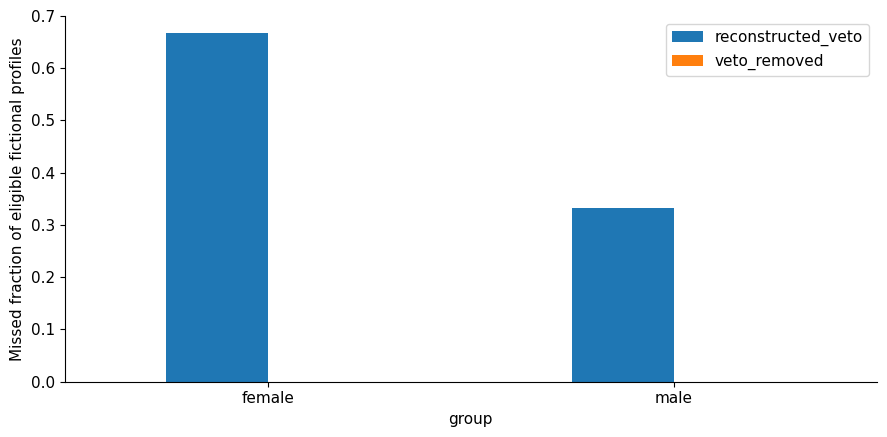

In [7]:
data["decision_revised"]=data.work_sample.ge(70).astype(int)
after=audit_table(data.assign(decision=data.decision_revised),group="sex_rule_category")
display(Markdown("**Same grid after removing the reconstructed veto**"))
display(after[["n","TP","FP","FN","TN","selection_rate","FNR","FPR"]])
assert data.decision_revised.eq(data.y).all()
assert data.groupby("work_sample").decision_revised.nunique().eq(1).all()
recovered=data.loc[data.decision_legacy.eq(0)&data.decision_revised.eq(1)]
print("Recovered eligible fictional profiles:",len(recovered))
assert len(recovered)==9
plot=pd.DataFrame({"reconstructed_veto":before.FNR,"veto_removed":after.FNR})
plot.plot.bar();plt.ylabel("Missed fraction of eligible fictional profiles")
plt.xticks(rotation=0);plt.tight_layout();plt.show()

### 1.8 Ethical issues, evidence and action

| Problem | Recognition | Concrete response |
|---|---|---|
| Explicit age and sex conditions | Rule inspection and boundary pairs | Remove unjustified vetoes and review every branch before release. |
| Labeling past rejection as “suitable” | Target provenance shows a policy decision instead of performance | Validate a relevant, accessible assessment independently. |
| Missing applicant sampling frame | Source contains counts of affected applicants but no denominator | Request appropriate audit records and avoid invented population rates. |
| Birth-date collection and privacy | Screening asks for data unnecessary to the job decision | Minimize collection, restrict audit access, document retention and permissible use. |
| Organizational accountability | Applicants cannot understand or contest exclusion | Assign a decision owner, remedy route and monitored review process. |
| Narrow identity coverage | Rule handles only two reported categories | Document uncertainty and consult affected people when designing comprehensive policies. |

The main lesson is that automation can implement discriminatory policy even without a complex model. Replacing the software with a newer AI would not by itself remove an unjustified rule. Every operational decision needs a documented purpose and accountable owner.

**Core-class output:** the four-age boundary table, a trace of one wrongful exclusion in the reconstructed grid, a before/after rule test, and a statement of what the official source does not provide.

In [8]:
project_data=data.copy()
print("Part 1 rule audit finished; the actual employer's applicant-level data remain unavailable.")

Part 1 rule audit finished; the actual employer's applicant-level data remain unavailable.


## Part 2 — Final project, extension and self-study

### 2.1 A question you can test

**Starting question:** Which rule and data-collection changes prevent unjustified exclusion, and what tests would reveal remaining proxies?

**Independent unit:** one fictional applicant profile and its controlled age/category variants. **Suggested primary quantity:** controlled decision flips and wrongful exclusions against a justified reference. Define the sign, reference group and practical effect threshold before comparing results. The primary criterion should follow a specific harm, rather than whichever number is easiest to equalize.

Possible extensions:
- Add missing values and accessibility cases to the rule specification.
- Examine a graduation-year proxy without assuming it is justified.
- Develop a rule-audit specification and monitored appeal procedure.

**TODO:** Write a protocol containing your decision, population, stakeholders, hypothesis, primary metric, independent unit, data permissions, split/resampling plan, intervention and evidence that could reverse your recommendation. Separate empirically checkable statements from ethical choices.

In [9]:
PROJECT_SPEC={
    "case_id":"C3","question":"TODO: one falsifiable question",
    "independent_unit":'one fictional applicant profile and its controlled age/category variants',"primary_metric":'controlled decision flips and wrongful exclusions against a justified reference',
    "reference_group":"TODO","practical_effect_threshold":None,
    "validation_plan":"TODO","intervention":"TODO",
    "ethics_and_label_assumptions":"TODO","seed":SEED,
}
PROJECT_DIR=ROOT/"reports"/'C3'
PROJECT_DIR.mkdir(parents=True,exist_ok=True)
display(pd.Series(PROJECT_SPEC,name="Your research protocol"))

case_id                                                                        C3
question                                           TODO: one falsifiable question
independent_unit                one fictional applicant profile and its contro...
primary_metric                  controlled decision flips and wrongful exclusi...
reference_group                                                              TODO
practical_effect_threshold                                                   None
validation_plan                                                              TODO
intervention                                                                 TODO
ethics_and_label_assumptions                                                 TODO
seed                                                                           42
Name: Your research protocol, dtype: object

### 2.2 TODO work packages and implementation hints

1. **TODO: Write a precise rule specification.** Define valid inputs, unsupported categories, missing ages and error handling. Hint: an unknown input should trigger explicit review rather than a silently invented rejection policy.
2. **TODO: Add boundary and metamorphic tests.** Test exactly 54/55 and 59/60, and controlled edits holding qualification fixed. Hint: specify invariance of job-related decisions to an irrelevant protected cue.
3. **TODO: Evaluate a proxy mechanism.** Introduce a disclosed graduation-year or career-gap branch in a separate synthetic variant. Hint: show how removing age alone could leave an age-related effect. Never infer actual age from real applicants without a justified audit purpose.
4. **TODO: Validate the alternative target.** Replace the simple threshold with a multi-criterion teaching rubric and at least two documented assessments. Hint: assess accessibility and disagreement, not only agreement percentages.
5. **TODO: Analyze coverage sensitivity.** Vary the fictional age mix and show how aggregate rates change while the rule remains fixed. Hint: distinguish a design distribution from a sampled population and avoid binomial inference on an exhaustive test grid.
6. **TODO: Produce an actionable process recommendation.** Identify owner, monitoring, retention, review and applicant challenge route. Hint: include evidence requirements before claiming remediation of the real case.

### 2.3 Validity, uncertainty and data stewardship

No real iTutorGroup applicant records, model outputs or performance labels are included. The invented work sample is not the actual employer rubric. The source describes a U.S. enforcement case settled in 2023; use it to examine a mechanism, and distinguish that from legal advice about another jurisdiction.

Keep related observations together. Fit transformations and models on training data, choose thresholds on validation data, and examine a final test set once. If you revise after seeing test results, obtain a fresh holdout or call the analysis exploratory. Report practical effect sizes and sample support with any interval. A deterministic teaching grid supports exhaustive rule checks and assumption sensitivity, not a population confidence interval.

Where you propose human annotation, specify the rubric, accessible instructions, disagreement resolution, annotator time, compensation and opt-out. Record disagreement rather than treating a majority vote as automatically unbiased truth. Avoid collecting real applicant résumés simply to enlarge a class project.

### 2.4 Further reading and independent study

Read the full EEOC release and trace each case claim to it. Compare computational treatment testing with AGG §3: https://www.gesetze-im-internet.de/agg/__3.html. Study how target leakage and reproducing historical decisions differ from evaluating justified job criteria.

**Self-study challenge:** Identify one claim that these data cannot support. Design the smallest additional consented or fictional audit that could test it, including the sampling unit, target definition and privacy constraints.

In [10]:
def student_extension(data,spec):
    """TODO: return results_table, assumptions, uncertainty, limitations and recommendation."""
    raise NotImplementedError("Implement your extension; the guided baseline is only Part 1.")

RUN_STUDENT_PROJECT=False  # Enable only after implementing the extension.
if RUN_STUDENT_PROJECT:
    result=student_extension(project_data.copy(),PROJECT_SPEC)
    assert {"results_table","limitations","recommendation"}.issubset(result)
    display(result["results_table"])

### Final-project submission and assessment

Submit an extended notebook, an environment specification, a processing log, a data card, and a 1,500–2,500 word report. Include a reproducible baseline, one substantive extension, an uncertainty or assumption-sensitivity analysis, and a recommendation whose limits follow from the data. A project that simply reruns the worked cells needs further work.

Use the supplied protocol, data-card and audit-report templates. Keep immutable inputs unchanged and save your derived results in your case's `reports/` folder. List exclusions, missingness policies and failed runs. If you use AI assistance, identify it and verify its code and claims yourself. Explain one numerical calculation and one design choice in an oral defence without relying on an AI-generated answer.

| Assessment component | Weight | Evidence |
|---|---:|---|
| Question and justified fairness objective | 15% | Specific decision, affected people, independent unit and hypothesis |
| Data provenance, quality and ethical reasoning | 20% | Source, permitted use, missingness, label limitations and concrete actions |
| Reproducible implementation | 25% | Correct denominators, runnable pipeline and appropriate validation |
| Substantive extension and uncertainty | 25% | New analysis or intervention, effect size, assumptions and sensitivity |
| Interpretation and communication | 15% | Supported recommendation, tradeoffs and honest evidence boundaries |

**Peer review:** Another team should reproduce one figure and one number, identify its numerator and denominator, and challenge one assumption. Check an empty subgroup or zero denominator: an undefined error rate must remain undefined. Explain whose burden increases if your chosen criterion improves.

**Final check:** clean execution; sources cited; all TODOs addressed; no raw data silently modified; thresholds and positive-decision direction named; project extension demonstrated; conclusions distinguish descriptive, causal and legal claims; monitoring and appeal owner identified.